In [1]:
#Question 1.1
import re, unicodedata, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, learning_curve
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.feature_selection import chi2
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

In [2]:
df_raw = pd.read_json("research_abstracts.json")
print(df_raw.shape)
print(df_raw.dtypes)
print(df_raw.isna().sum())
print("duplicate abstracts:", df_raw.Abstract.duplicated().sum())
print(df_raw.Label.value_counts())
df_raw.head()

(1138, 3)
DOI         object
Abstract    object
Label       object
dtype: object
DOI         4
Abstract    0
Label       0
dtype: int64
duplicate abstracts: 13
Label
classical    900
ai           238
Name: count, dtype: int64


,DOI,Abstract,Label
0,10.1155/2021/1071145,Forward-looking forecasting of the inflation r...,ai
1,10.1007/s43546-022-00384-2,Our study examined the disaggregation of infla...,ai
2,10.1002/for.2667,This paper develops a dynamic factor model tha...,classical
3,10.1007/s42973-021-00091-x,"In this paper, I use a simple SIR Macro model ...",classical
4,10.1007/s40258-012-0003-z,BackgroundGame theory is useful for identifyin...,classical


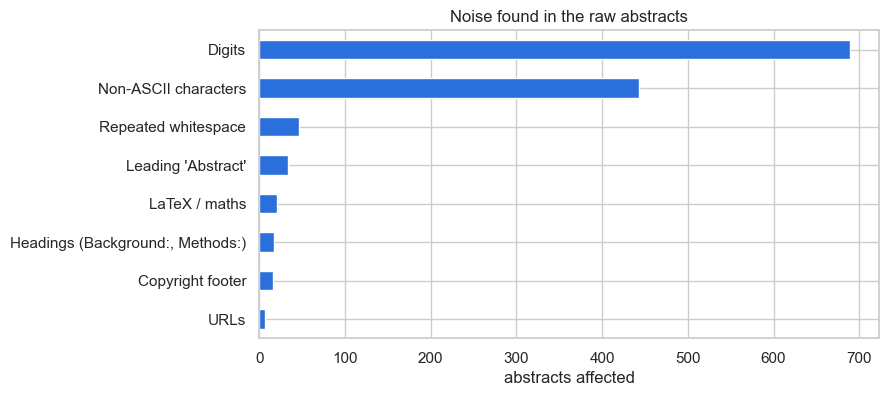

In [3]:
patterns = {
    "Copyright footer": r"©|copyright|all rights reserved",
    "Leading 'Abstract'": r"^\s*abstract",
    "Headings (Background:, Methods:)": r"\b(background|objectives?|purpose|methods?|results?|conclusions?)\s*:",
    "LaTeX / maths": r"\$|\\[a-z]+",
    "URLs": r"https?://|www\.",
    "Non-ASCII characters": r"[^\x00-\x7f]",
    "Digits": r"\d",
    "Repeated whitespace": r"\s{2,}",
}
audit = pd.Series({k: df_raw.Abstract.str.contains(v, flags=re.I, regex=True).sum() for k, v in patterns.items()}).sort_values()
ax = audit.plot.barh(figsize=(8, 4), color="#2a6fdb")
ax.set_title("Noise found in the raw abstracts")
ax.set_xlabel("abstracts affected")
plt.show()

In [4]:
extra_stop = {"abstract", "paper", "article", "study", "studies", "research", "work", "present", "presents",
              "propose", "proposed", "result", "results", "conclusion", "conclusions", "method", "methods",
              "background", "objective", "objectives", "purpose", "copyright", "wiley", "sons", "ltd",
              "elsevier", "springer", "rights", "reserved", "author", "authors", "journal", "doi"}
STOP = set(ENGLISH_STOP_WORDS) | extra_stop
KEEP = {"series", "species", "bias", "gas", "news", "analysis", "basis", "hypothesis", "economics", "statistics", "dynamics", "physics"}
IRREG = {"analyses": "analysis", "hypotheses": "hypothesis", "crises": "crisis", "bases": "basis"}

def lemma(w):
    if w in KEEP or len(w) <= 3:
        return w
    if w in IRREG:
        return IRREG[w]
    if w.endswith("ies") and len(w) > 4:
        return w[:-3] + "y"
    if w.endswith(("sses", "shes", "ches", "xes", "zes")):
        return w[:-2]
    if w.endswith("s") and not w.endswith(("ss", "us", "is", "ics")):
        return w[:-1]
    return w

def clean_text(text):
    if not isinstance(text, str):
        return ""
    t = re.sub(r"<[^>]+>|&[a-z]+;|&#\d+;", " ", text)
    t = re.sub(r"(copyright\s*)?(©|\(c\)).{0,80}?(ltd\.?|inc\.?|elsevier|springer|wiley|ieee|all rights reserved)\.?", " ", t, flags=re.I)
    t = re.sub(r"(https?://\S+|www\.\S+|\b10\.\d{4,}/\S+)", " ", t, flags=re.I)
    t = re.sub(r"\S+@\S+\.\S+", " ", t)
    t = re.sub(r"^\s*(abstract|summary)\s*[:.\-]?\s*", "", t, flags=re.I)
    t = re.sub(r"\b(background|objectives?|purpose|methods?|results?|conclusions?|aims?|findings)\s*:", " ", t, flags=re.I)
    t = re.sub(r"\$[^$]{0,200}\$|\\[a-zA-Z]+\{?[^}\s]*\}?", " ", t)
    t = t.replace("\u2013", "-").replace("\u2014", "-").replace("\u2212", "-")
    t = unicodedata.normalize("NFKD", t).encode("ascii", "ignore").decode("ascii").lower()
    t = t.replace("-", " ").replace("/", " ")
    t = re.sub(r"[^a-z\s]", " ", t)
    tokens = [lemma(w) for w in t.split() if len(w) >= 3 and w not in STOP]
    return " ".join(tok for tok in tokens if tok not in STOP and len(tok) >= 3)

In [5]:
cosmo_pattern = r"inflaton|cosmolog|primordial|preheating|slow[- ]roll|tachyonic|curvature spectrum|power spectra|f\(R\)|warm inflation|large-scale structure"

df = df_raw.copy()
n_start = len(df)
df = df[df.Abstract.notna() & (df.Abstract.str.strip() != "")]
df = df.drop_duplicates(subset="Abstract")
n_dups = n_start - len(df)
off_topic = df.Abstract.str.contains(cosmo_pattern, case=False, regex=True)
print("off-topic abstracts removed:", off_topic.sum())
df = df[~off_topic]
df["clean"] = df.Abstract.apply(clean_text)
df = df[df.clean.str.split().str.len() >= 5].reset_index(drop=True)
df["y"] = (df.Label == "ai").astype(int)
print(f"{n_start} -> {len(df)} abstracts ({n_dups} duplicates removed)")
print(df.Label.value_counts())

off-topic abstracts removed: 5
1138 -> 1120 abstracts (13 duplicates removed)
Label
classical    889
ai           231
Name: count, dtype: int64


RAW  : This paper develops a dynamic factor model that uses euro area country-specific information on output and inflation to estimate an area-wide measure of the output gap. Our model assumes that output and inflation can be decomposed into country-specific stochastic trends and a common cyclical component. Comovement in the trends is introduced by imposing a factor structure on the shocks to the latent 

CLEAN: develop dynamic factor model use euro area country specific information output inflation estimate area wide measure output gap model assume output inflation decomposed country specific stochastic trend common cyclical component comovement trend introduced imposing factor structure shock latent state introduce flexible stochastic volatility specification control heteroscedasticity measurement error


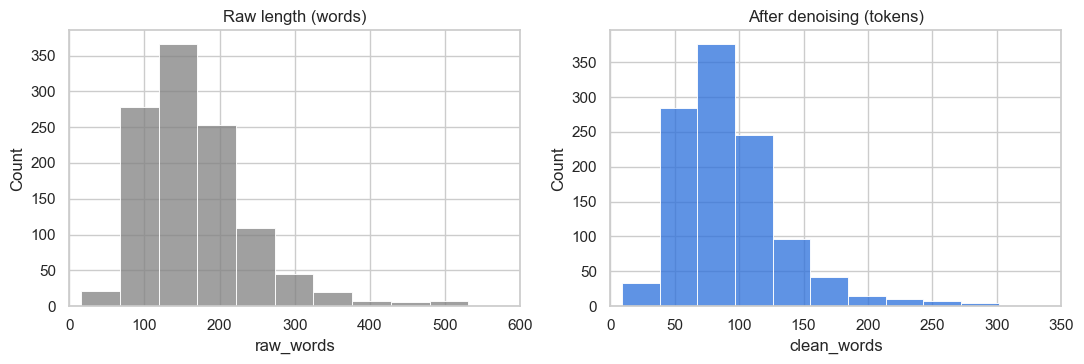

In [6]:
print("RAW  :", df.Abstract[2][:400], "\n")
print("CLEAN:", df.clean[2][:400])

df["raw_words"] = df.Abstract.str.split().str.len()
df["clean_words"] = df.clean.str.split().str.len()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(df.raw_words, bins=40, ax=ax[0], color="grey").set(title="Raw length (words)", xlim=(0, 600))
sns.histplot(df.clean_words, bins=40, ax=ax[1], color="#2a6fdb").set(title="After denoising (tokens)", xlim=(0, 350))
plt.tight_layout()
plt.show()

In [7]:
#Question 1.2
train, test = train_test_split(df, test_size=0.20, stratify=df.y, random_state=RANDOM_STATE)
train, test = train.reset_index(drop=True), test.reset_index(drop=True)
print(train.shape, test.shape, train.y.mean().round(3), test.y.mean().round(3))

(896, 7) (224, 7) 0.206 0.205


In [8]:
def doi_prefix(d):
    return d.split("/")[0] if isinstance(d, str) and d.startswith("10.") else ("ssrn.com" if isinstance(d, str) else "missing")

train["doi_prefix"] = train.DOI.apply(doi_prefix)
top = train.doi_prefix.value_counts().head(8).index
ct = pd.crosstab(train.doi_prefix.where(train.doi_prefix.isin(top), "other"), train.Label)
ct["share_ai"] = (ct["ai"] / ct.sum(axis=1)).round(2)
display(ct.sort_values("share_ai", ascending=False))

tab = pd.crosstab(train.doi_prefix, train.Label)
chi2_stat, p, _, _ = chi2_contingency(tab)
cramers_v = np.sqrt(chi2_stat / (tab.values.sum() * (min(tab.shape) - 1)))
print(f"chi2={chi2_stat:.1f}  p={p:.2e}  Cramer's V={cramers_v:.2f}")

skf = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
make_lr = lambda: LogisticRegression(C=10, class_weight="balanced", max_iter=2000)
doi_model = Pipeline([("v", TfidfVectorizer(analyzer="char", ngram_range=(3, 6))), ("m", make_lr())])
txt_model = Pipeline([("v", TfidfVectorizer(min_df=2, sublinear_tf=True)), ("m", make_lr())])
f1_doi = cross_validate(doi_model, train.DOI.fillna("missing"), train.y, cv=skf, scoring="f1")["test_score"].mean()
f1_txt = cross_validate(txt_model, train.clean, train.y, cv=skf, scoring="f1")["test_score"].mean()
print(f"CV F1 (ai), DOI only: {f1_doi:.3f} | Abstract only: {f1_txt:.3f}")

Label,ai,classical,share_ai
doi_prefix,,,
10.1109,39,7,0.85
10.48550,18,6,0.75
10.1007,17,41,0.29
other,61,213,0.22
10.1016,22,133,0.14
10.2139,21,211,0.09
10.1111,3,36,0.08
10.1002,2,25,0.07
10.1080,2,39,0.05


chi2=401.4  p=1.76e-25  Cramer's V=0.67
CV F1 (ai), DOI only: 0.531 | Abstract only: 0.785


TF-IDF matrix: (896, 6044)
39 of 6044 terms are significantly class-dependent


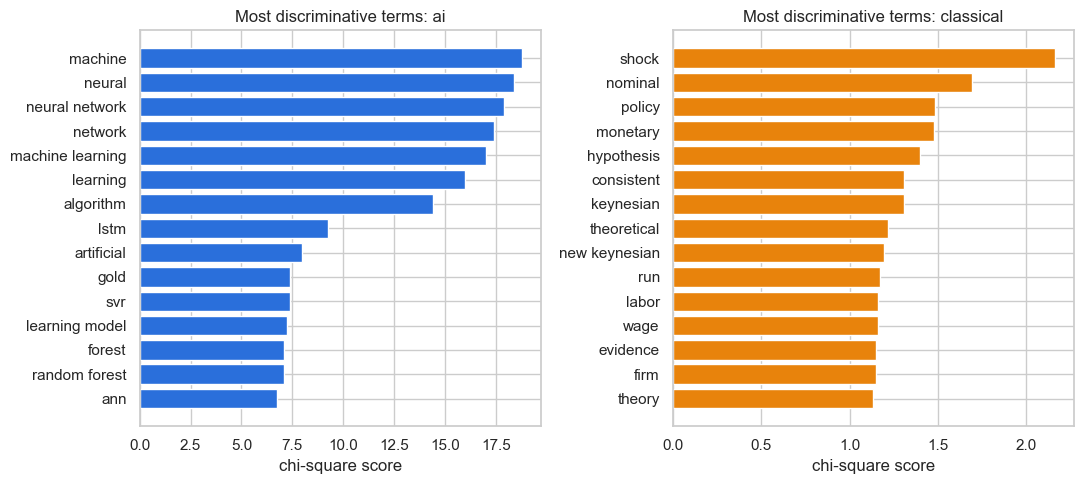

,term,chi2,p,leans
0,machine,18.761450,0.000015,ai
1,neural,18.403451,0.000018,ai
2,neural network,17.897585,0.000023,ai
3,network,17.387169,0.000030,ai
4,machine learning,17.026193,0.000037,ai
5,learning,16.002009,0.000063,ai
6,algorithm,14.419436,0.000146,ai
7,lstm,9.236677,0.002372,ai
8,artificial,7.981180,0.004727,ai
9,gold,7.402575,0.006513,ai


In [9]:
vec = TfidfVectorizer(min_df=3, ngram_range=(1, 2), sublinear_tf=True)
Xtr = vec.fit_transform(train.clean)
terms = np.array(vec.get_feature_names_out())
print("TF-IDF matrix:", Xtr.shape)

chi_scores, chi_p = chi2(Xtr, train.y)
ai_mean = np.asarray(Xtr[train.y.values == 1].mean(0)).ravel()
cl_mean = np.asarray(Xtr[train.y.values == 0].mean(0)).ravel()
rank = pd.DataFrame({"term": terms, "chi2": chi_scores, "p": chi_p, "leans": np.where(ai_mean > cl_mean, "ai", "classical")})
rank = rank.sort_values("chi2", ascending=False).reset_index(drop=True)
print((rank.p < 0.05).sum(), "of", len(rank), "terms are significantly class-dependent")

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
for a, lab, col in zip(ax, ["ai", "classical"], ["#2a6fdb", "#e8830c"]):
    r = rank[rank.leans == lab].head(15).iloc[::-1]
    a.barh(r.term, r.chi2, color=col)
    a.set_title(f"Most discriminative terms: {lab}")
    a.set_xlabel("chi-square score")
plt.tight_layout()
plt.show()
rank.head(15)

In [10]:
meta = pd.DataFrame({
    "n_tokens": train.clean.str.split().str.len(),
    "raw_words": train.Abstract.str.split().str.len(),
    "avg_word_len": train.clean.apply(lambda s: np.mean([len(w) for w in s.split()])),
    "type_token_ratio": train.clean.apply(lambda s: len(set(s.split())) / max(1, len(s.split()))),
    "digit_share": train.Abstract.apply(lambda s: sum(c.isdigit() for c in s) / len(s)),
})
meta_corr = pd.Series({c: np.corrcoef(meta[c], train.y)[0, 1] for c in meta}).round(3)
Xd = Xtr.toarray()
term_corr = np.array([np.corrcoef(Xd[:, j], train.y)[0, 1] if Xd[:, j].std() > 0 else 0 for j in range(Xd.shape[1])])
print(meta_corr)
print("strongest term |r|:", np.abs(term_corr).max().round(2), "->", terms[np.abs(term_corr).argmax()])

n_tokens            0.044
raw_words           0.036
avg_word_len       -0.131
type_token_ratio    0.007
digit_share        -0.001
dtype: float64
strongest term |r|: 0.48 -> machine


In [11]:
#Question 1.3
Xtr_text, ytr = train.clean, train.y.values
Xte_text, yte = test.clean, test.y.values

baseline = Pipeline([("tfidf", TfidfVectorizer(min_df=2)), ("nb", MultinomialNB())])
floor = DummyClassifier(strategy="most_frequent")
baseline.fit(Xtr_text, ytr)
floor.fit(Xtr_text, ytr)

def report(model, X, y, name):
    pred = model.predict(X)
    score = model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)
    return {"set": name,
            "accuracy": accuracy_score(y, pred),
            "balanced_acc": balanced_accuracy_score(y, pred),
            "precision_ai": precision_score(y, pred, zero_division=0),
            "recall_ai": recall_score(y, pred),
            "f1_ai": f1_score(y, pred),
            "f1_macro": f1_score(y, pred, average="macro"),
            "roc_auc": roc_auc_score(y, score),
            "pr_auc": average_precision_score(y, score)}

perf = pd.DataFrame([report(baseline, Xtr_text, ytr, "train"),
                     report(baseline, Xte_text, yte, "test"),
                     report(floor, Xte_text, yte, "test: majority-class floor")]).set_index("set").round(3)
perf

,accuracy,balanced_acc,precision_ai,recall_ai,f1_ai,f1_macro,roc_auc,pr_auc
set,,,,,,,,
train,0.856,0.651,1.0,0.303,0.465,0.691,0.975,0.942
test,0.835,0.598,1.0,0.196,0.327,0.617,0.914,0.808
test: majority-class floor,0.795,0.500,0.0,0.000,0.000,0.443,0.500,0.205


In [12]:
scoring = {"accuracy": "accuracy", "f1_ai": "f1", "f1_macro": "f1_macro", "roc_auc": "roc_auc"}
cv = cross_validate(baseline, Xtr_text, ytr, cv=skf, scoring=scoring, return_train_score=True)
cv_table = pd.DataFrame({m: [cv[f"train_{m}"].mean(), cv[f"test_{m}"].mean(), cv[f"test_{m}"].std()] for m in scoring},
                        index=["train mean", "validation mean", "validation std"]).round(3)
cv_table

,accuracy,f1_ai,f1_macro,roc_auc
train mean,0.846,0.407,0.659,0.978
validation mean,0.814,0.173,0.534,0.917
validation std,0.012,0.091,0.048,0.018


              precision    recall  f1-score   support

   classical      0.828     1.000     0.906       178
          ai      1.000     0.196     0.327        46

    accuracy                          0.835       224
   macro avg      0.914     0.598     0.617       224
weighted avg      0.863     0.835     0.787       224



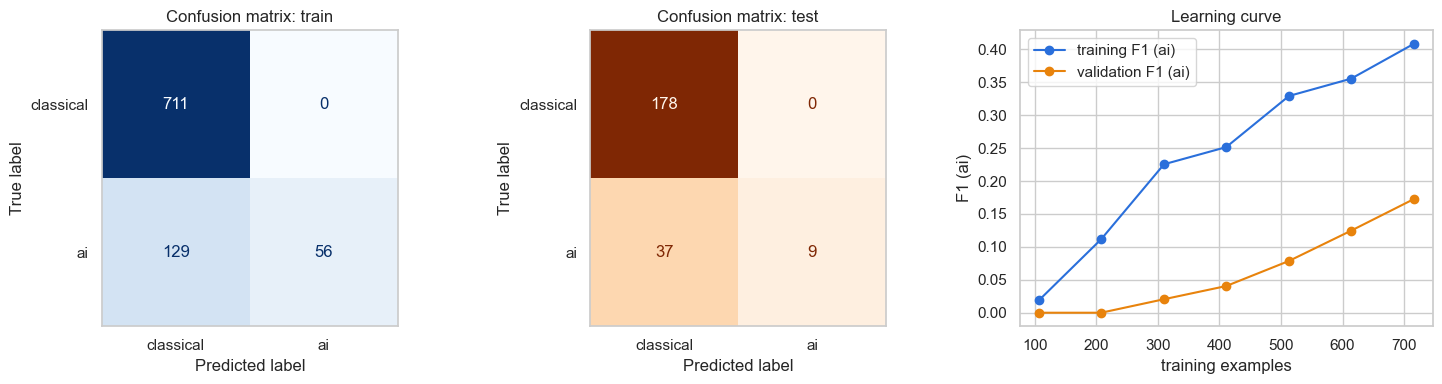

In [13]:
pred_te = baseline.predict(Xte_text)
print(classification_report(yte, pred_te, target_names=["classical", "ai"], digits=3))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ConfusionMatrixDisplay(confusion_matrix(ytr, baseline.predict(Xtr_text)), display_labels=["classical", "ai"]).plot(ax=ax[0], colorbar=False, cmap="Blues")
ax[0].set_title("Confusion matrix: train")
ax[0].grid(False)
ConfusionMatrixDisplay(confusion_matrix(yte, pred_te), display_labels=["classical", "ai"]).plot(ax=ax[1], colorbar=False, cmap="Oranges")
ax[1].set_title("Confusion matrix: test")
ax[1].grid(False)

sizes, tr_s, va_s = learning_curve(baseline, Xtr_text, ytr, cv=skf, scoring="f1",
                                   train_sizes=np.linspace(0.15, 1, 7), random_state=RANDOM_STATE)
ax[2].plot(sizes, tr_s.mean(1), "o-", color="#2a6fdb", label="training F1 (ai)")
ax[2].plot(sizes, va_s.mean(1), "o-", color="#e8830c", label="validation F1 (ai)")
ax[2].set_xlabel("training examples")
ax[2].set_ylabel("F1 (ai)")
ax[2].set_title("Learning curve")
ax[2].legend()
plt.tight_layout()
plt.show()

In [14]:
#Question 2.1
import time
import joblib
from sklearn.base import clone
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import roc_curve

In [15]:
models = {
    "Baseline: Multinomial NB": baseline,
    "Logistic Regression": Pipeline([("t", TfidfVectorizer(min_df=2)), ("m", LogisticRegression(max_iter=2000))]),
    "Linear SVM": Pipeline([("t", TfidfVectorizer(min_df=2)), ("m", LinearSVC())]),
    "Complement NB": Pipeline([("t", TfidfVectorizer(min_df=2)), ("m", ComplementNB())]),
    "Random Forest": Pipeline([("t", TfidfVectorizer(min_df=2)), ("m", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1))]),
    "Gradient Boosting": Pipeline([("t", TfidfVectorizer(min_df=2)), ("m", GradientBoostingClassifier(random_state=RANDOM_STATE))]),
}

def get_scores(model, X):
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)

rows, fitted = [], {}
for name, m in models.items():
    cv = cross_validate(m, Xtr_text, ytr, cv=skf, scoring={"f1": "f1", "roc_auc": "roc_auc"})
    m.fit(Xtr_text, ytr)
    fitted[name] = m
    pred, score = m.predict(Xte_text), get_scores(m, Xte_text)
    rows.append({"model": name,
                 "CV F1 (ai)": cv["test_f1"].mean(),
                 "CV F1 std": cv["test_f1"].std(),
                 "train F1 (ai)": f1_score(ytr, m.predict(Xtr_text)),
                 "test accuracy": accuracy_score(yte, pred),
                 "test precision (ai)": precision_score(yte, pred, zero_division=0),
                 "test recall (ai)": recall_score(yte, pred),
                 "test F1 (ai)": f1_score(yte, pred),
                 "test F1 macro": f1_score(yte, pred, average="macro"),
                 "test ROC-AUC": roc_auc_score(yte, score)})
results = pd.DataFrame(rows).set_index("model").round(3)
results

,CV F1 (ai),CV F1 std,train F1 (ai),test accuracy,test precision (ai),test recall (ai),test F1 (ai),test F1 macro,test ROC-AUC
model,,,,,,,,,
Baseline: Multinomial NB,0.173,0.091,0.465,0.835,1.000,0.196,0.327,0.617,0.914
Logistic Regression,0.337,0.079,0.625,0.879,1.000,0.413,0.585,0.757,0.926
Linear SVM,0.744,0.034,0.997,0.924,0.939,0.674,0.785,0.869,0.920
Complement NB,0.660,0.042,0.858,0.897,0.926,0.543,0.685,0.812,0.914
Random Forest,0.723,0.024,1.000,0.929,1.000,0.652,0.789,0.873,0.961
Gradient Boosting,0.736,0.035,0.943,0.933,0.943,0.717,0.815,0.887,0.947


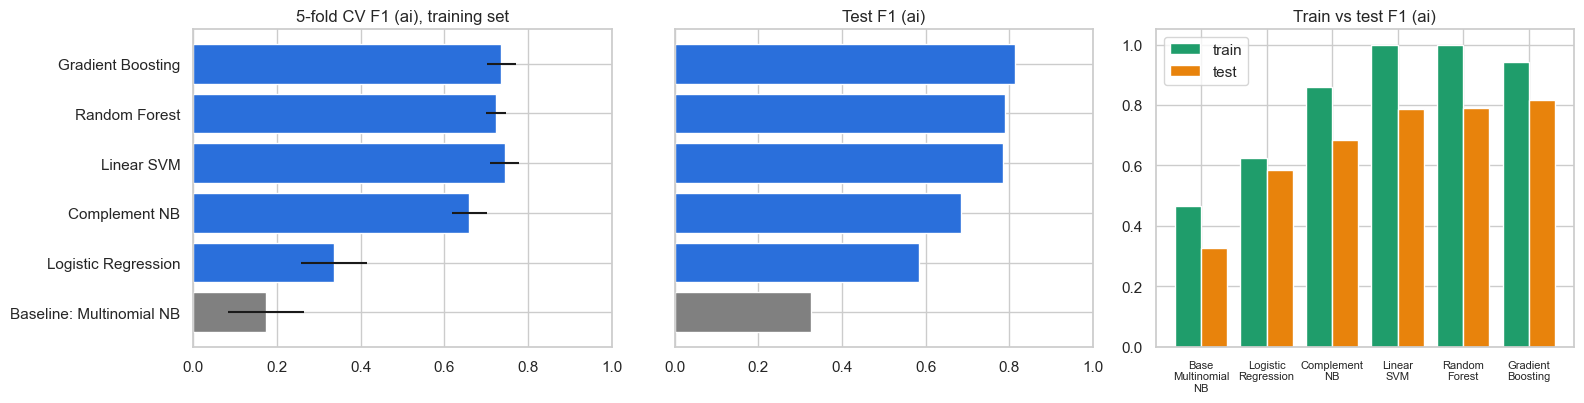

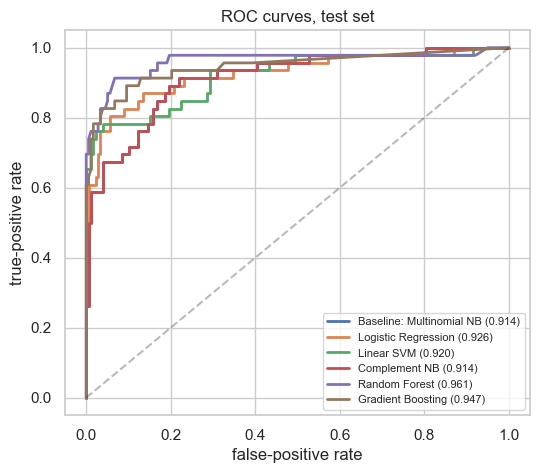

In [16]:
order = results.sort_values("test F1 (ai)")
colors = ["grey" if "Baseline" in n else "#2a6fdb" for n in order.index]

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].barh(order.index, order["CV F1 (ai)"], xerr=order["CV F1 std"], color=colors)
ax[0].set_title("5-fold CV F1 (ai), training set")
ax[0].set_xlim(0, 1)
ax[1].barh(order.index, order["test F1 (ai)"], color=colors)
ax[1].set_title("Test F1 (ai)")
ax[1].set_xlim(0, 1)
ax[1].set_yticklabels([])
x = np.arange(len(order))
ax[2].bar(x - 0.2, order["train F1 (ai)"], 0.4, color="#1f9d6b", label="train")
ax[2].bar(x + 0.2, order["test F1 (ai)"], 0.4, color="#e8830c", label="test")
ax[2].set_xticks(x)
ax[2].set_xticklabels([n.replace("Baseline: ", "Base\n").replace(" ", "\n", 1) for n in order.index], fontsize=8)
ax[2].set_title("Train vs test F1 (ai)")
ax[2].legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 5))
for name, m in fitted.items():
    fpr, tpr, _ = roc_curve(yte, get_scores(m, Xte_text))
    plt.plot(fpr, tpr, lw=2, label=f"{name} ({roc_auc_score(yte, get_scores(m, Xte_text)):.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.3)
plt.xlabel("false-positive rate")
plt.ylabel("true-positive rate")
plt.title("ROC curves, test set")
plt.legend(fontsize=8)
plt.show()

In [17]:
#Question 2.2
pipe = Pipeline([("t", TfidfVectorizer()), ("m", LinearSVC())])
grid = {
    "t__ngram_range": [(1, 1), (1, 2)],
    "t__min_df": [1, 2, 3],
    "t__sublinear_tf": [True, False],
    "m__C": [0.1, 0.3, 1, 3, 10],
    "m__class_weight": [None, "balanced"],
}
t0 = time.time()
gs = GridSearchCV(pipe, grid, scoring="f1", cv=skf, n_jobs=-1).fit(Xtr_text, ytr)
print(f"{len(gs.cv_results_['params'])} configurations in {time.time() - t0:.0f}s")
print("best CV F1 (ai):", round(gs.best_score_, 3))
print(gs.best_params_)

120 configurations in 11s
best CV F1 (ai): 0.794
{'m__C': 0.3, 'm__class_weight': 'balanced', 't__min_df': 1, 't__ngram_range': (1, 1), 't__sublinear_tf': True}


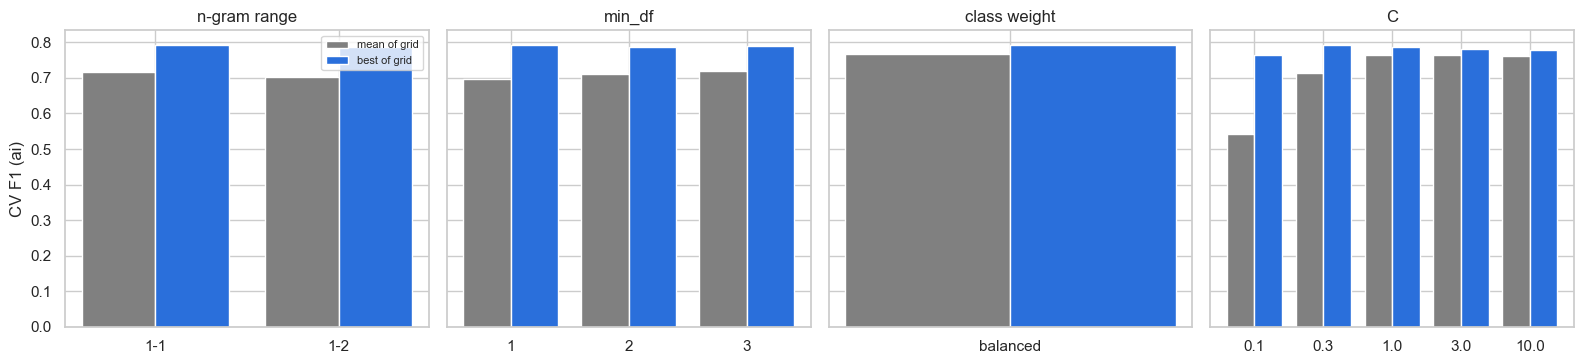

In [18]:
cvr = pd.DataFrame(gs.cv_results_)
cvr["ngrams"] = cvr.param_t__ngram_range.apply(lambda t: f"{t[0]}-{t[1]}")
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for a, col, title in zip(ax, ["ngrams", "param_t__min_df", "param_m__class_weight", "param_m__C"],
                         ["n-gram range", "min_df", "class weight", "C"]):
    g = cvr.groupby(col).agg(best=("mean_test_score", "max"), mean=("mean_test_score", "mean"))
    xs = np.arange(len(g))
    a.bar(xs - 0.2, g["mean"], 0.4, color="grey", label="mean of grid")
    a.bar(xs + 0.2, g["best"], 0.4, color="#2a6fdb", label="best of grid")
    a.set_xticks(xs)
    a.set_xticklabels([str(i) for i in g.index])
    a.set_title(title)
ax[0].set_ylabel("CV F1 (ai)")
ax[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

,CV F1 (ai),test precision (ai),test recall (ai),test F1 (ai),test ROC-AUC
configuration,,,,,
Baseline NB (Q1),0.173,1.000,0.196,0.327,0.914
"Linear SVM, default (2.1)",0.744,0.939,0.674,0.785,0.920
"Linear SVM, TUNED (2.2)",0.794,0.837,0.783,0.809,0.942


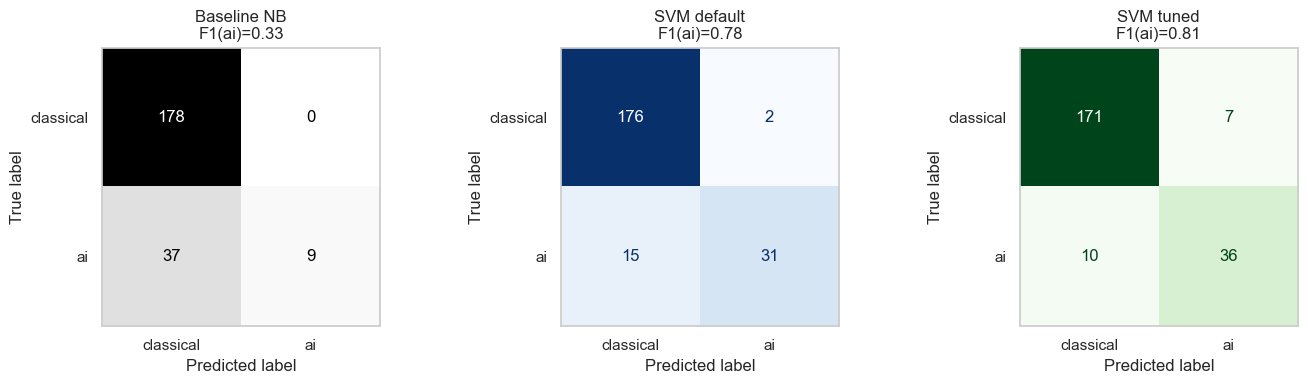

In [19]:
tuned = gs.best_estimator_
compare = []
for label, m in [("Baseline NB (Q1)", fitted["Baseline: Multinomial NB"]),
                 ("Linear SVM, default (2.1)", fitted["Linear SVM"]),
                 ("Linear SVM, TUNED (2.2)", tuned)]:
    pred = m.predict(Xte_text)
    compare.append({"configuration": label,
                    "CV F1 (ai)": cross_validate(m, Xtr_text, ytr, cv=skf, scoring="f1")["test_score"].mean(),
                    "test precision (ai)": precision_score(yte, pred, zero_division=0),
                    "test recall (ai)": recall_score(yte, pred),
                    "test F1 (ai)": f1_score(yte, pred),
                    "test ROC-AUC": roc_auc_score(yte, get_scores(m, Xte_text))})
compare = pd.DataFrame(compare).set_index("configuration").round(3)
display(compare)

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, (label, m), cmap in zip(ax, [("Baseline NB", fitted["Baseline: Multinomial NB"]),
                                    ("SVM default", fitted["Linear SVM"]),
                                    ("SVM tuned", tuned)], ["Greys", "Blues", "Greens"]):
    ConfusionMatrixDisplay(confusion_matrix(yte, m.predict(Xte_text)), display_labels=["classical", "ai"]).plot(ax=a, colorbar=False, cmap=cmap)
    a.set_title(f"{label}\nF1(ai)={f1_score(yte, m.predict(Xte_text)):.2f}")
    a.grid(False)
plt.tight_layout()
plt.show()

In [20]:
#Question 2.3
all_text = pd.concat([Xtr_text, Xte_text])
all_y = np.concatenate([ytr, yte])
final = Pipeline([
    ("t", clone(tuned.named_steps["t"])),
    ("m", CalibratedClassifierCV(clone(tuned.named_steps["m"]), cv=5)),
]).fit(all_text, all_y)
joblib.dump(final, "model.joblib")

demo = clean_text("We forecast consumer price inflation with LSTM neural networks and random forests.")
print(final.predict_proba([demo])[0].round(3))

[0. 1.]


In [21]:
%%writefile app.py
import re
import unicodedata
import joblib
import streamlit as st
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

extra_stop = {"abstract", "paper", "article", "study", "studies", "research", "work", "present", "presents",
              "propose", "proposed", "result", "results", "conclusion", "conclusions", "method", "methods",
              "background", "objective", "objectives", "purpose", "copyright", "wiley", "sons", "ltd",
              "elsevier", "springer", "rights", "reserved", "author", "authors", "journal", "doi"}
STOP = set(ENGLISH_STOP_WORDS) | extra_stop
KEEP = {"series", "species", "bias", "gas", "news", "analysis", "basis", "hypothesis", "economics", "statistics", "dynamics", "physics"}
IRREG = {"analyses": "analysis", "hypotheses": "hypothesis", "crises": "crisis", "bases": "basis"}


def lemma(w):
    if w in KEEP or len(w) <= 3:
        return w
    if w in IRREG:
        return IRREG[w]
    if w.endswith("ies") and len(w) > 4:
        return w[:-3] + "y"
    if w.endswith(("sses", "shes", "ches", "xes", "zes")):
        return w[:-2]
    if w.endswith("s") and not w.endswith(("ss", "us", "is", "ics")):
        return w[:-1]
    return w


def clean_text(text):
    if not isinstance(text, str):
        return ""
    t = re.sub(r"<[^>]+>|&[a-z]+;|&#\d+;", " ", text)
    t = re.sub(r"(copyright\s*)?(©|\(c\)).{0,80}?(ltd\.?|inc\.?|elsevier|springer|wiley|ieee|all rights reserved)\.?", " ", t, flags=re.I)
    t = re.sub(r"(https?://\S+|www\.\S+|\b10\.\d{4,}/\S+)", " ", t, flags=re.I)
    t = re.sub(r"\S+@\S+\.\S+", " ", t)
    t = re.sub(r"^\s*(abstract|summary)\s*[:.\-]?\s*", "", t, flags=re.I)
    t = re.sub(r"\b(background|objectives?|purpose|methods?|results?|conclusions?|aims?|findings)\s*:", " ", t, flags=re.I)
    t = re.sub(r"\$[^$]{0,200}\$|\\[a-zA-Z]+\{?[^}\s]*\}?", " ", t)
    t = t.replace("\u2013", "-").replace("\u2014", "-").replace("\u2212", "-")
    t = unicodedata.normalize("NFKD", t).encode("ascii", "ignore").decode("ascii").lower()
    t = t.replace("-", " ").replace("/", " ")
    t = re.sub(r"[^a-z\s]", " ", t)
    tokens = [lemma(w) for w in t.split() if len(w) >= 3 and w not in STOP]
    return " ".join(tok for tok in tokens if tok not in STOP and len(tok) >= 3)


@st.cache_resource
def load_model():
    return joblib.load("model.joblib")


model = load_model()

st.title("Researchly Research Abstract Classifier")
st.write("This app classifies research abstracts as either AI-related or classical research.")

abstract = st.text_area("Enter research abstract:", height=220)

if st.button("Classify Abstract"):
    cleaned = clean_text(abstract)
    if len(cleaned.split()) < 5:
        st.warning("Please enter a longer abstract.")
    else:
        p_ai = float(model.predict_proba([cleaned])[0, 1])
        st.subheader("Prediction")
        if p_ai >= 0.5:
            st.success("The abstract is classified as: artificial intelligence")
        else:
            st.success("The abstract is classified as: classical research")
        st.caption(f"Probability of AI-related: {p_ai:.1%}")
        st.progress(p_ai)

Writing app.py


In [ ]:
!pip install streamlit
!streamlit run app.py